# Floating (pocket) circular transmon

`CircTransmonFloating` -- a circular disc split along its local **y** axis into a
LEFT and a RIGHT half-island, shunted at the centre by one Josephson junction
(green in the plots). The corners where the split edge meets the rim are
filleted (`gap_corner_radius`).

This notebook builds the four layouts from `build_design.py`:

1. **bare split** -- disc + centre JJ
2. **shunt IDC** -- the split filled with an interdigitated capacitor (one comb
   galvanically part of each island) to raise the island-to-island shunt C
3. **+ readout claw + charge line** -- a hanger-readout claw on the right island
   and an XY drive pad on the left island (must stay clear of the +-90 deg split)
4. **coupled pair** -- two floating transmons joined by `CapNInterdigitalRound`,
   which flares tangentially onto the outer arc of the facing island of each

Blue = metal, red hatch = ground-plane cutout, green = junction. No FEM here.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from build_design import single_transmon, coupled_pair, _design_bounds_mm
from render_geometry import render, sanity_checks


def show(design, title, figsize=(7, 7), xlim=None, ylim=None):
    fig, ax = plt.subplots(figsize=figsize)
    render(design, ax)
    mnx, mny, mxx, mxy = _design_bounds_mm(design)
    ax.set_xlim(*(xlim or (mnx - 0.03, mxx + 0.03)))
    ax.set_ylim(*(ylim or (mny - 0.03, mxy + 0.03)))
    ax.set_title(title)
    ax.grid(alpha=0.15)
    plt.show()

## 1. Bare split

metal nets (>300 um2): 2   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


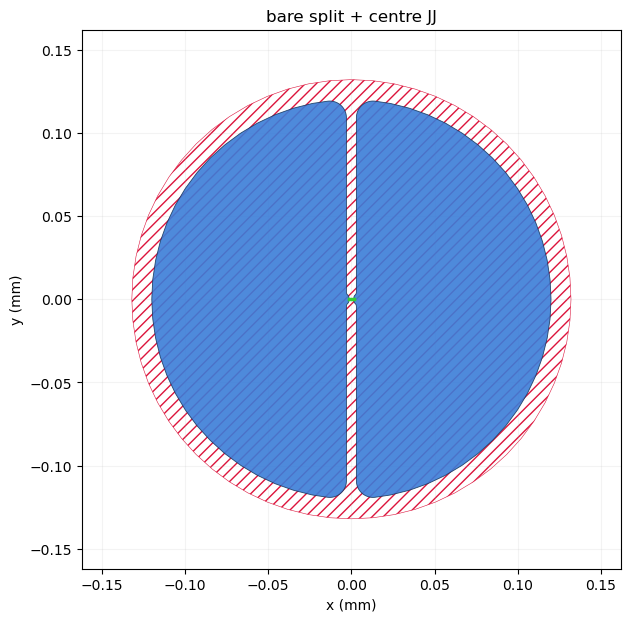

In [2]:
d_bare = single_transmon()
sanity_checks(d_bare)
show(d_bare, "bare split + centre JJ")

## 2. Split filled with an interdigitated shunt capacitor

`shunt_idc.make_idc=True`. `finger_count='0'` auto-fills the whole diameter at
the finger pitch; `island_gap` is widened (`ISLAND_GAP_IDC_UM`) to fit them. The
JJ still bridges a thin central band left free between the innermost fingers.

metal nets (>300 um2): 2   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


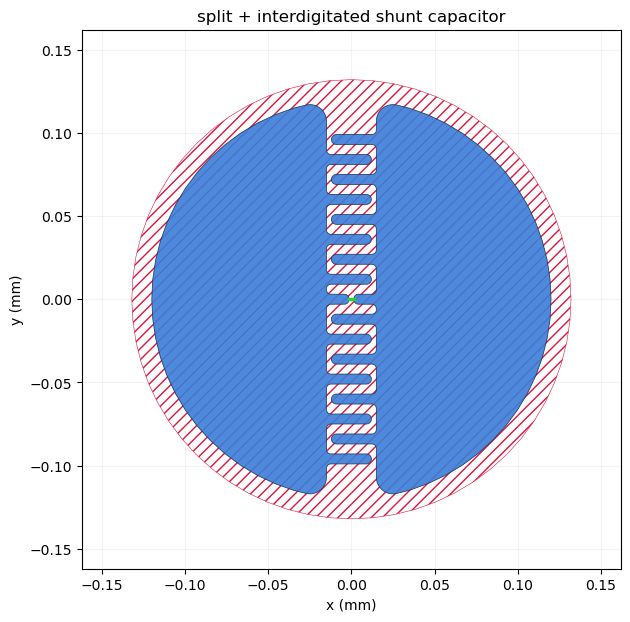

In [3]:
d_idc = single_transmon(idc=True)
sanity_checks(d_idc)
show(d_idc, "split + interdigitated shunt capacitor")

## 3. + hanger-readout claw and charge line

Both are the stock `CircTransmon` elements, reused: `claw_a` at 0 deg (right
island), the charge line at 180 deg (left island). `_check_island_angles()`
rejects a claw / charge line whose angle would straddle the split.

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


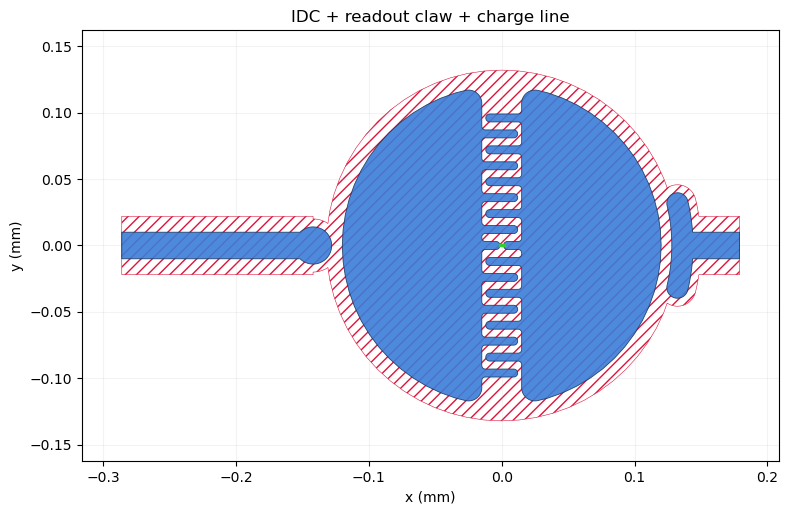

In [4]:
d_full = single_transmon(idc=True, claw=True, charge=True)
sanity_checks(d_full)
show(d_full, "IDC + readout claw + charge line", figsize=(9, 6))

## 4. Two floating transmons + CapNInterdigitalRound coupler

`|pos_x| = D` is derived from the coupler geometry (`_transmon_offset_um`) so the
coupler's tangent-flare tip reaches each island's rim. `island_radius =
pad_radius`, so the coupler treats each half-island's arc exactly like a full
circular pad.

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]
components: ['Q1', 'Q2', 'coupler']  junctions: 2


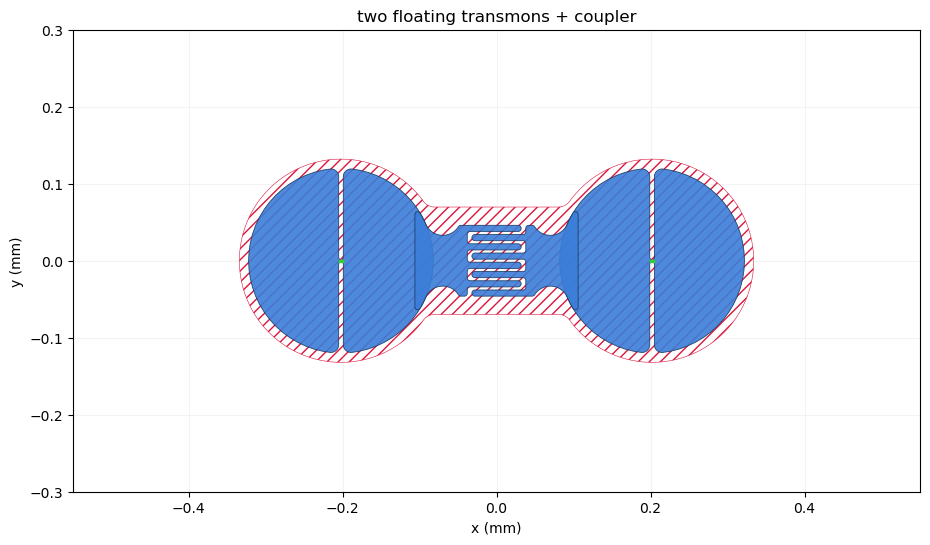

In [5]:
d_pair = coupled_pair()
sanity_checks(d_pair)
print("components:", list(d_pair.components.keys()),
      " junctions:", len(d_pair.qgeometry.tables["junction"]))
show(d_pair, "two floating transmons + coupler", figsize=(13, 6),
     xlim=(-0.55, 0.55), ylim=(-0.3, 0.3))

### zoom on the Q1 -- coupler junction

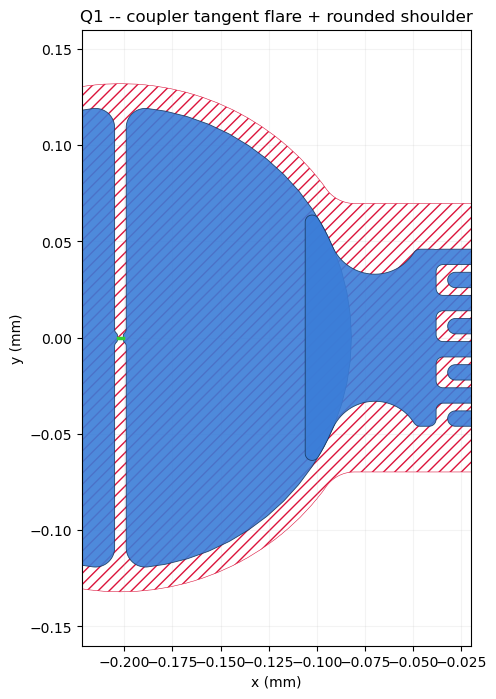

In [6]:
Dmm = -float(str(d_pair.components["Q1"].options["pos_x"]).replace("um", "")) * 1e-3
show(d_pair, "Q1 -- coupler tangent flare + rounded shoulder", figsize=(8, 8),
     xlim=(-Dmm - 0.02, -0.02), ylim=(-0.16, 0.16))

## The IDC coupled pair

`coupled_pair(idc=True)` -- both transmons get the interdigitated shunt cap.

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


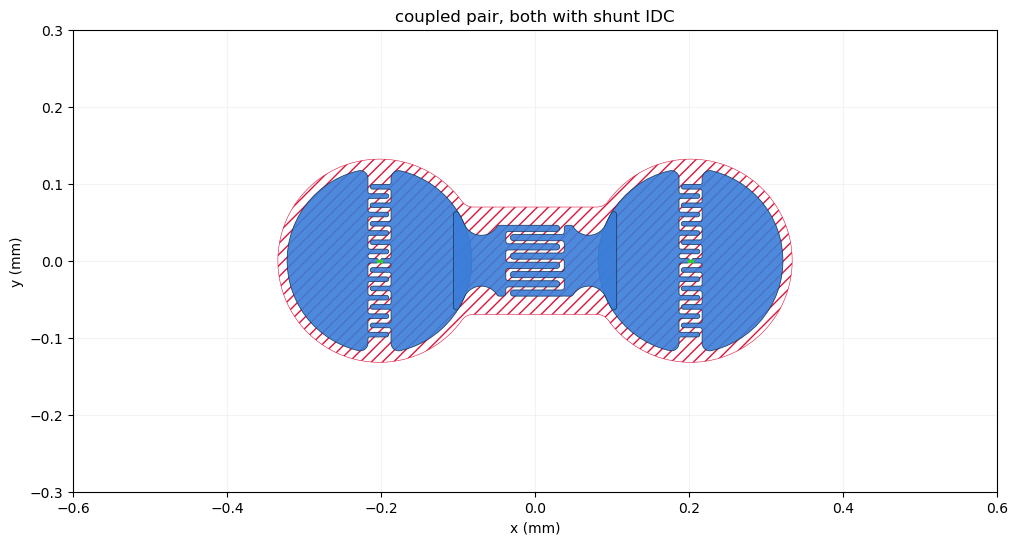

In [7]:
d_pair_idc = coupled_pair(idc=True)
sanity_checks(d_pair_idc)
show(d_pair_idc, "coupled pair, both with shunt IDC", figsize=(13, 6),
     xlim=(-0.6, 0.6), ylim=(-0.3, 0.3))

## 5. Coupler ports + arbitrary orientation

Two additions to `CircTransmonFloating`:

* **filleted JJ tabs** -- the metal tabs that carry the junction to the centre
  now have rounded corners where they emerge from each island edge (a clamped
  morphological closing, so the fillet can never bridge the JJ gap).
* **`port_r` / `port_l`** -- set `make_port=True` to emit a pin on that island's
  outer arc at `angle` (right island: within 70 deg of 0; left island: within
  70 deg of 180), normal radially outward. It is a routing anchor -- a coupler
  or CPW can snap to it instead of the hand-computed `_transmon_offset_um` maths.

Orientation: the whole component rotates freely via `orientation` (any angle),
but the split is always along local y and the JJ along local x, so a coupler
must land on one island's ~140 deg outer arc -- at most one neighbour per
island. Point a coupler elsewhere by rotating the whole transmon.

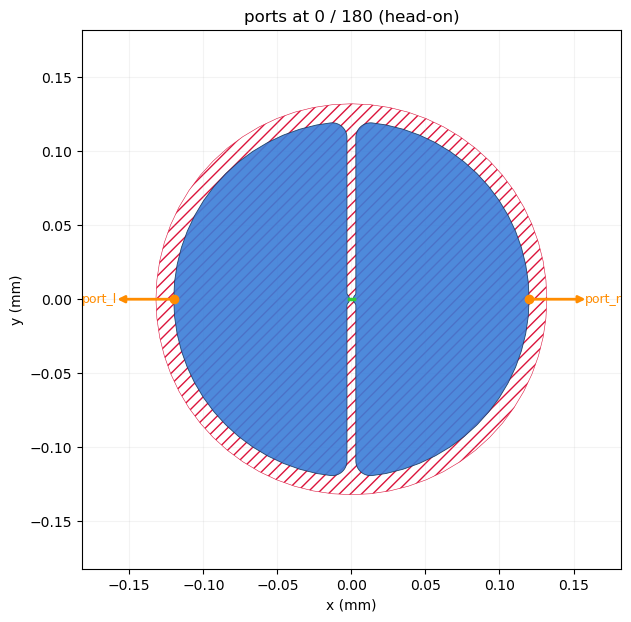

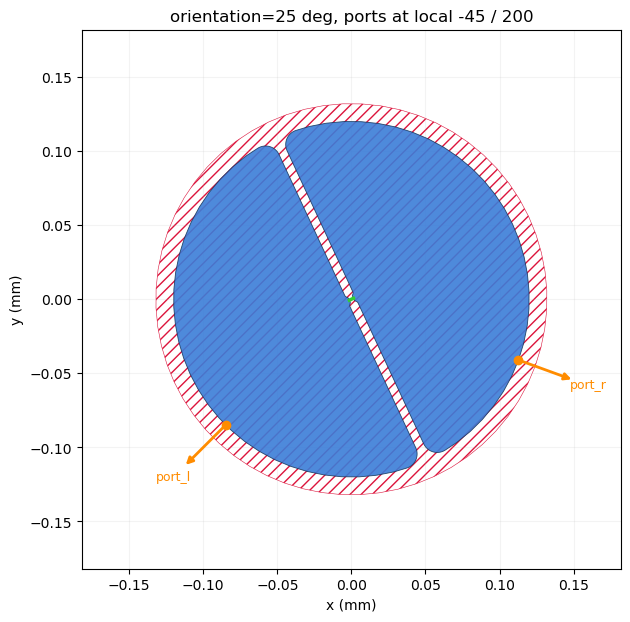

In [8]:
import numpy as np
from qiskit_metal import designs, Dict
from qiskit_metal.qlibrary.qubits.circle_transmon_floating import CircTransmonFloating
from build_design import floating_options, _size_chip


def with_ports(orientation=0, port_r=None, port_l=None):
    d = designs.DesignPlanar({}, overwrite_enabled=True)
    o = floating_options(0.0, orientation=orientation)
    if port_r is not None:
        o["port_r"] = Dict(make_port=True, angle=f"{port_r}")
    if port_l is not None:
        o["port_l"] = Dict(make_port=True, angle=f"{port_l}")
    CircTransmonFloating(d, "Q", options=o)
    d.rebuild()
    _size_chip(d, margin=2.4)
    return d


def show_ports(d, title):
    fig, ax = plt.subplots(figsize=(7, 7))
    render(d, ax)
    q = d.components["Q"]
    for name, pin in q.pins.items():
        x, y = pin["middle"]
        nx, ny = pin["normal"]
        ax.annotate("", xy=(x + nx * 0.04, y + ny * 0.04), xytext=(x, y),
                    arrowprops=dict(arrowstyle="-|>", color="darkorange", lw=2))
        ax.plot(x, y, "o", color="darkorange", ms=6)
        ax.text(x + nx * 0.05, y + ny * 0.05, name, color="darkorange",
                ha="center", va="center", fontsize=9)
    mnx, mny, mxx, mxy = _design_bounds_mm(d)
    ax.set_xlim(mnx - 0.05, mxx + 0.05)
    ax.set_ylim(mny - 0.05, mxy + 0.05)
    ax.set_title(title)
    ax.grid(alpha=0.15)
    plt.show()


show_ports(with_ports(port_r=0, port_l=180), "ports at 0 / 180 (head-on)")
show_ports(with_ports(orientation=25, port_r=-45, port_l=200),
           "orientation=25 deg, ports at local -45 / 200")


## 6. A coupled pair at an arbitrary orientation

`coupled_pair(orientation_deg=θ)` rotates the whole 3-component assembly about
the origin: the coupling axis runs at θ and **both** transmons are turned by θ
too, so each one's facing island still meets the coupler head-on (the split gap
stays perpendicular to the axis, 90° clear of the contact point). Same `D`, same
coupler geometry — only the global transform changes. This is how you place a
floating-transmon link along any lattice direction.

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


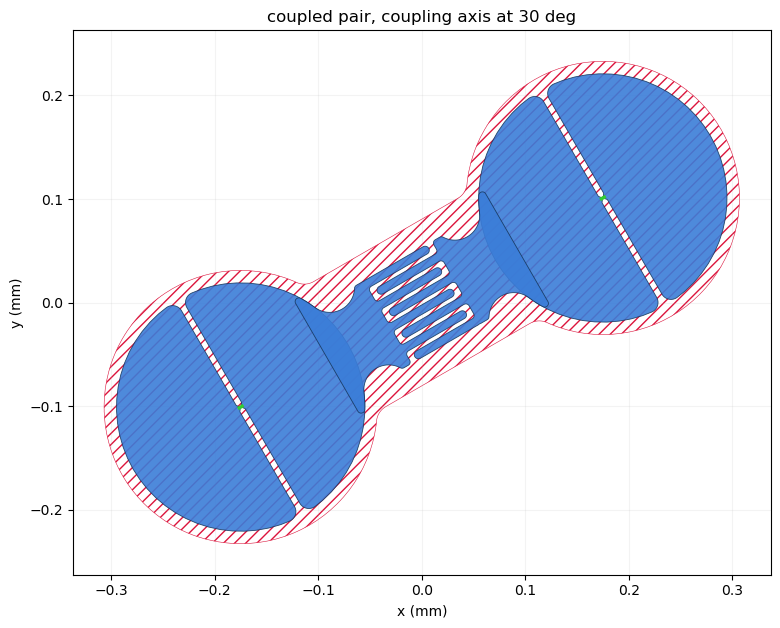

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


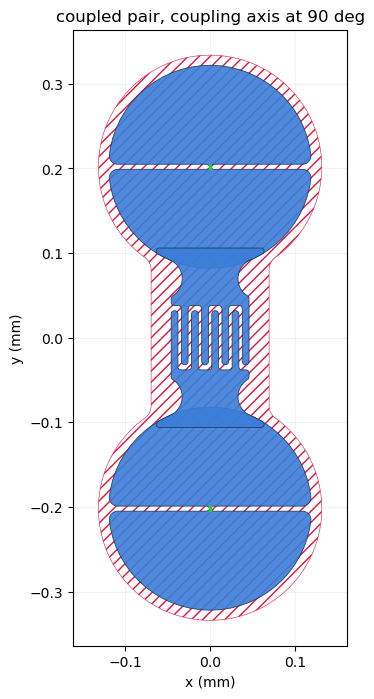

metal nets (>300 um2): 4   min gap between them: 3.00 um
ground pieces (>1e-7 mm2): 1   [want 1 = fully connected]


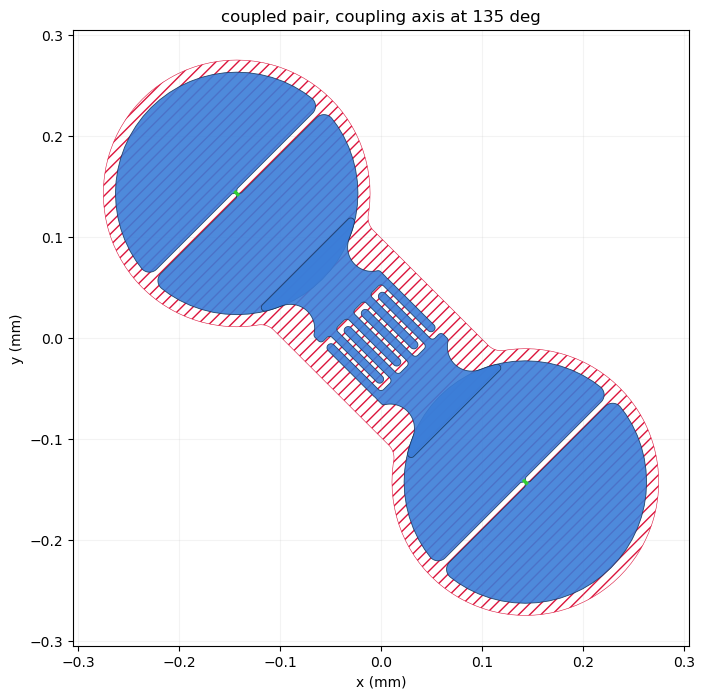

In [9]:
for theta in (30, 90, 135):
    d = coupled_pair(orientation_deg=theta)
    sanity_checks(d)
    show(d, f"coupled pair, coupling axis at {theta} deg", figsize=(9, 8))


## Interactive (MetalGUI)

`MetalGUI` opens a **separate Qt window** (not inline) and switches matplotlib to
a Qt backend, so keep it after every inline plot. qiskit_metal pipes every Qt
platform warning through its `metal` logger with a full stack trace — cosmetic
noise under an offscreen / X-forwarded display — so this cell quiets that logger
first. Skip this cell if you don't have a display.

In [10]:
import os, logging
logging.getLogger("metal").setLevel(logging.ERROR)   # silence the Qt-warning stack traces

_disp = os.environ.get("DISPLAY", "") or os.environ.get("WAYLAND_DISPLAY", "")
if _disp and os.environ.get("QT_QPA_PLATFORM") == "offscreen":
    del os.environ["QT_QPA_PLATFORM"]                 # let a real window open

if not _disp:
    print("[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots "
          "above already show the geometry;\n    MetalGUI is only for click-through "
          "inspection + GDS export.")
else:
    get_ipython().run_line_magic("gui", "qt")
    from qiskit_metal import MetalGUI
    design = coupled_pair()
    gui = MetalGUI(design)
    gui.rebuild()
    gui.autoscale()

[!] no DISPLAY / WAYLAND_DISPLAY -- skipping MetalGUI. The inline plots above already show the geometry;
    MetalGUI is only for click-through inspection + GDS export.
